In [1]:
import numpy as np
from rich import print
from contingency import Contingent
import matplotlib.pyplot as plt

from contingency.plots import PR_contour

np.set_printoptions(formatter={'float_kind':"{:.5g}".format})
y_true = np.array([0,1,0,0,1]).astype(bool)
y_pred = np.array([0,1,0,1,0]).astype(bool)

y_prob = np.array([0.1,0.8,0.1,.7,.25])

# M = Contingent(y_pred = y_pred, y_true=y_true)
M = Contingent.from_scalar(y_true, y_prob)

In [2]:
M.F2

array([0.76923, 0.76923, 0.90909, 0.5, 0.55556, 0])

np.float64(1.5)

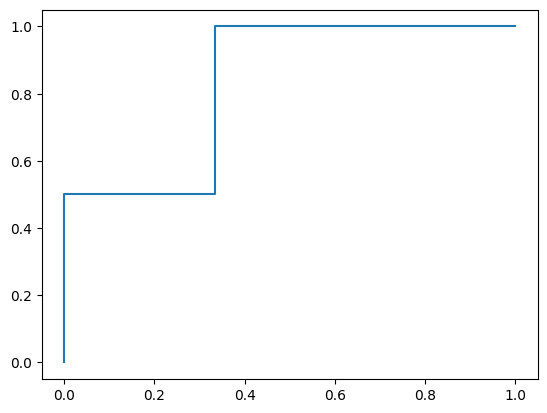

In [3]:

plt.plot(1-M.TNR, M.TPR)
M.imbalance

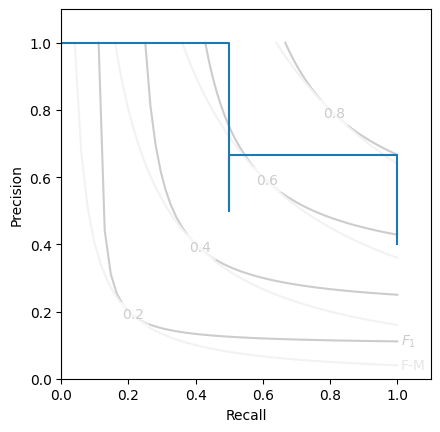

In [24]:
PR_contour()
plt.gca().set_aspect(1)
plt.step(M.recall, M.precision, where='post')

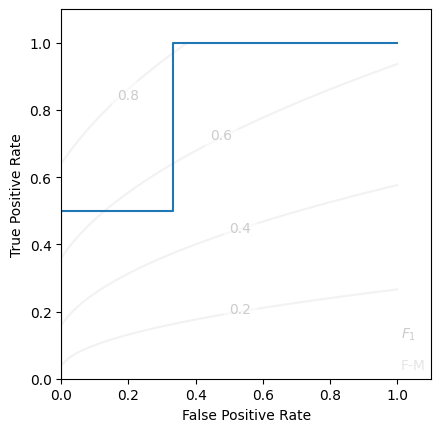

In [25]:

def _fm_isoline_fpr(t, r, num_points=50):
    fpr_line = np.linspace(0, np.minimum(1, (1 - t**2) / (t**2 * r)), num_points)
    tpr_line = (t**2 + np.sqrt(t**4 + 4 * t**2 * r * fpr_line)) / 2.
    return fpr_line, tpr_line

def _f1_isoline_fpr(t,r,num_points=50):
    fpr_f1 = np.linspace(0, np.minimum(1, 2*(1-t)/(t*r)))
    tpr_f1 = np.minimum(t*(r*fpr_f1+1) / (2 - t),1)
    return fpr_f1, tpr_f1

def ROC_contour(r, ax=None):
    """Generate a nice-looking contour plot for ROC (TPR vs FNR)
    
    Args: 
        r: class imbalance ratio (required for F1)
    
    """

    if ax is None: 
        ax = plt.gca()
    thres = np.linspace(0.2, 0.8, num=4)
    lines, labels = [], []
    for t in thres:
        fpr_f1,tpr_f1 = _f1_isoline_fpr(t,r)
        fpr_fm, tpr_fm = _fm_isoline_fpr(t,r)
        
        # (l,) = ax.plot(fpr_f1, tpr_f1, color="0.8")
        (l,) = ax.plot(fpr_fm, tpr_fm, color="0.95")
        ax.annotate(
            f"{t:0.1f}",
            xy=((fpr_f1.max()+fpr_f1.min())/2, (tpr_f1.max()+tpr_f1.min())/2),
            color='0.8',
            bbox=dict(facecolor='white', linewidth=0, alpha=0.5)
        )

    ax.annotate(r"$F_1$", xy=(1.01, 0.1*(r+1)/(2-.1)-0.01), color='0.8')
    ax.annotate(r"F-M", xy=(1.01, 0.2**2-0.01), color='0.9')
    ax.set(
        ylim=(0,1.1),
        xlim=(0,1.1),
        ylabel='True Positive Rate',
        xlabel='False Positive Rate', 
        aspect=1,
    )
ROC_contour(M.imbalance)
plt.plot(1-M.TNR, M.TPR)

In [9]:
from contingency.contingent import trapezoid
# -trapezoid(M.TPR, x=M.FPR)
M.expected('auc'), M.expected('aps')

(np.float64(0.8333333333333333), np.float64(0.8333333333333333))

In [12]:
M.TPR
M.FPR

masked_array(data=[1.0, 1.0, 0.33333333333333337, 0.33333333333333337,
                   0.0, 0.0],
             mask=[False, False, False, False, False, False],
       fill_value=1e+20)